# AML Detection v4: more context, guilt-by-association, stacking, and a high-recall mode

v3 reached F1 ≈ 0.53 (the transaction-level model was the best). v4 attacks the remaining misses:

| Upgrade | Why it should help |
|---|---|
| **Context-window features** | Laundering often *splits* money (scatter) or *merges* it (gather). New features measure how much arrived just **before** a transfer and how much left just **after** it, plus bursts around it |
| **Guilt by association** (label-aware features) | Laundering accounts usually sit next to other laundering accounts. For each account we count its neighbours that are *known* laundering accounts (**training labels only**) |
| **Stacking meta-learner** | A small model trained on the validation set (5-fold CV) learns how to combine GAT, GBM and transaction model, and how much to trust a high score from a very busy account |
| **Bigger transaction model** | 150 negatives per positive instead of 60, larger trees |
| **Operating points** | The same scores, thresholded two ways: **balanced (max F1)** and **high-recall (recall maximised subject to a precision floor)**, plus a table of recall at several precision floors |

**About the label-aware features (read this for your report).** They are standard semi-supervised practice: in deployment you *do* know which accounts were already confirmed as laundering. Validation/test labels are never used, and each transaction's features exclude its other endpoint's label, so there is no leakage. But they assume that a large share of accounts already has known labels (here 70%). Set `label_reveal_frac` lower to simulate fewer known labels, or `use_label_features=False` to reproduce a v3-style result (a good ablation for your report).

In [36]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("torch_geometric") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch-geometric"])

import glob, random, time, copy
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix)
from torch_geometric.data import Data
from torch_geometric.nn import GATConv
from torch_geometric.loader import NeighborLoader

CFG = dict(
    seed=42,
    max_rows=None,            # e.g. 500_000 for a quick trial run
    reverse_edges=True,       # let accounts also "see" who they paid
    nbrs=[10, 5],             # neighbours sampled per hop (2 hops = 2 GAT layers)
    batch_size=512,
    hidden=32, heads=4, dropout=0.3,
    lr=2e-3, weight_decay=1e-4,
    epochs=50, patience=8,
    neg_per_pos=10,           # negatives per positive in every training epoch
    val_monitor_neg_frac=0.25, # fraction of val negatives used for fast per-epoch monitoring
    fwd_window_hours=24,       # 'forwarded quickly' = re-sent within this many hours
    edge_neg_per_pos=150,      # negatives per positive for the transaction-level model
    use_label_features=True,   # guilt-by-association from TRAIN labels (see intro)
    label_reveal_frac=1.0,     # share of training labels treated as 'known' (lower = harder)
    min_precision=0.40         # precision floor for the high-recall operating point
)
SEED = CFG["seed"]
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| PyTorch:", torch.__version__)

Device: cpu | PyTorch: 2.11.0+cpu


## 1. Load the data

In [37]:
COLS = ["timestamp","from_bank","src_acc","to_bank","dst_acc","amt_recv","cur_recv",
        "amt_paid","cur_paid","fmt","is_laundering"]
matches = glob.glob("/kaggle/input/**/HI-Small_Trans.csv", recursive=True)
if not matches:
    raise FileNotFoundError("Attach the dataset containing HI-Small_Trans.csv via Kaggle 'Add Input'.")
CSV_PATH = matches[0]
# header=0 + names=COLS replaces the raw header (which has two columns both called 'Account')
df = pd.read_csv(CSV_PATH, header=0, names=COLS, nrows=CFG["max_rows"])
df = df.dropna(subset=["from_bank","src_acc","to_bank","dst_acc","is_laundering"]).reset_index(drop=True)
print("Using:", CSV_PATH, "| shape:", df.shape)
print(df.head(3))

Using: /kaggle/input/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml/HI-Small_Trans.csv | shape: (5078345, 11)
          timestamp  from_bank    src_acc  to_bank    dst_acc  amt_recv  \
0  2022/09/01 00:20         10  8000EBD30       10  8000EBD30   3697.34   
1  2022/09/01 00:20       3208  8000F4580        1  8000F5340      0.01   
2  2022/09/01 00:00       3209  8000F4670     3209  8000F4670  14675.57   

    cur_recv  amt_paid   cur_paid           fmt  is_laundering  
0  US Dollar   3697.34  US Dollar  Reinvestment              0  
1  US Dollar      0.01  US Dollar        Cheque              0  
2  US Dollar  14675.57  US Dollar  Reinvestment              0  


## 2. Account IDs, USD conversion, encodings

Amounts are in 15 currencies, so sums and ratios across currencies are meaningless unless converted.
The CSV contains cross-currency transfers that reveal the exchange rate (USD paid ÷ foreign amount received), so we estimate each currency's USD rate from those rows.

In [38]:
E = len(df)
src_key = df["from_bank"].astype(str) + "_" + df["src_acc"].astype(str)
dst_key = df["to_bank"].astype(str)   + "_" + df["dst_acc"].astype(str)
codes, uniques = pd.factorize(pd.concat([src_key, dst_key], ignore_index=True))
src = codes[:E].astype(np.int64); dst = codes[E:].astype(np.int64); N = len(uniques)
laund = df["is_laundering"].astype(int).to_numpy().astype(bool)
print(f"Accounts (nodes): {N:,} | Transactions (edges): {E:,} | laundering tx: {laund.sum():,}")

# ---- categorical encodings (shared vocabulary for the two currency columns) ----
currencies = sorted(set(df["cur_recv"].astype(str)) | set(df["cur_paid"].astype(str)))
formats    = sorted(df["fmt"].astype(str).unique())
cur_paid = pd.Categorical(df["cur_paid"].astype(str), categories=currencies).codes.astype(np.int64)
cur_recv = pd.Categorical(df["cur_recv"].astype(str), categories=currencies).codes.astype(np.int64)
fmt      = pd.Categorical(df["fmt"].astype(str),      categories=formats).codes.astype(np.int64)
C, Fm = len(currencies), len(formats)

# ---- estimate USD rate per currency from USD -> foreign transfers ----
rate = pd.Series(1.0, index=currencies)
m = (df["cur_paid"] == "US Dollar") & (df["cur_recv"] != "US Dollar") & (df["amt_recv"] > 0)
rate.update((df.loc[m, "amt_paid"] / df.loc[m, "amt_recv"]).groupby(df.loc[m, "cur_recv"]).median())
print("Estimated USD per 1 unit of currency:\n", rate.round(5).to_string())
rate_arr = rate.loc[currencies].to_numpy()
usd_paid = df["amt_paid"].clip(lower=0).to_numpy(np.float64) * rate_arr[cur_paid]
usd_recv = df["amt_recv"].clip(lower=0).to_numpy(np.float64) * rate_arr[cur_recv]

# ---- time ----
ts    = pd.to_datetime(df["timestamp"], format="%Y/%m/%d %H:%M")
hours = ((ts - ts.min()).dt.total_seconds() / 3600).to_numpy()
ts_norm = hours / max(hours.max(), 1e-9)
day = (hours // 24).astype(np.int64)

cross_cur  = (cur_paid != cur_recv).astype(np.float32)
cross_bank = (df["from_bank"].to_numpy() != df["to_bank"].to_numpy()).astype(np.float32)

Accounts (nodes): 515,088 | Transactions (edges): 5,078,345 | laundering tx: 5,177
Estimated USD per 1 unit of currency:
 Australian Dollar        0.70781
Bitcoin              11874.40249
Brazil Real              0.17710
Canadian Dollar          0.75798
Euro                     1.17178
Mexican Peso             0.04730
Ruble                    0.01285
Rupee                    0.01362
Saudi Riyal              0.26659
Shekel                   0.29612
Swiss Franc              1.09290
UK Pound                 1.29166
US Dollar                1.00000
Yen                      0.00949
Yuan                     0.14931


## 3. Node labels

In [39]:
y = np.zeros(N, dtype=np.float32)
y[src[laund]] = 1.0; y[dst[laund]] = 1.0
print(f"Positive accounts: {int(y.sum()):,} ({y.mean():.2%})")

Positive accounts: 6,357 (1.23%)


## 3a. Split accounts into train / validation / test

The split now happens *before* feature building, because the label-aware features may only use **training** labels.

In [40]:
all_nodes = np.arange(N)
train_nodes, tmp = train_test_split(all_nodes, test_size=0.30, random_state=SEED, stratify=y)
val_nodes, test_nodes = train_test_split(tmp, test_size=0.50, random_state=SEED, stratify=y[tmp])
is_train = np.zeros(N, bool); is_train[train_nodes] = True
is_vt = np.zeros(N, bool); is_vt[val_nodes] = True; is_vt[test_nodes] = True

## 3b. Transaction-level features (the key addition)

Every transaction is described *in context*:
- **Forwarding / layering**: time and amount ratio between this payment and the sender's most recent incoming payment; and between this payment and the receiver's next outgoing payment.
- **Pair structure**: how many times this pair transacts, and whether money also flows back (2-cycles).
- **Anomaly vs. habit**: percentile of this amount among the sender's / receiver's transactions.
- Time of day, weekday, format, currency, cross-bank / cross-currency flags.

In [41]:
# ---- pair structure ----
key = src * N + dst
uk, inv, cnt = np.unique(key, return_inverse=True, return_counts=True)
pair_cnt = cnt[inv].astype(np.float64)
s_u, d_u = uk // N, uk % N                                  # unique (sender, receiver) pairs
rkey = dst * N + src
j = np.minimum(np.searchsorted(uk, rkey), len(uk) - 1)
rev_cnt = np.where(uk[j] == rkey, cnt[j], 0).astype(np.float64)
jr = np.minimum(np.searchsorted(uk, d_u * N + s_u), len(uk) - 1)
recip_ok = (uk[jr] == d_u * N + s_u) & (s_u != d_u)         # pairs that also exist in reverse
del inv, cnt, key, rkey, j, jr

# ---- forwarding / layering via as-of joins ----
def asof(left_node, right_node, right_val, direction):
    L = pd.DataFrame({"node": left_node, "t": hours, "i": np.arange(E)}).sort_values("t")
    R = pd.DataFrame({"node": right_node, "t2": hours, "v": right_val}).sort_values("t2")
    M = pd.merge_asof(L, R, left_on="t", right_on="t2", by="node",
                      direction=direction, allow_exact_matches=False)
    i = M["i"].to_numpy(); delay = np.full(E, np.nan); val = np.full(E, np.nan)
    delay[i] = np.abs(M["t"].to_numpy() - M["t2"].to_numpy()); val[i] = M["v"].to_numpy()
    return delay, val

# sender's most recent earlier INCOMING payment
delay_prev, r_prev = asof(src, dst, usd_recv, "backward")
# receiver's next later OUTGOING payment
delay_next, p_next = asof(dst, src, usd_paid, "forward")
ratio_prev = usd_paid / (r_prev + 1e-9)
ratio_next = p_next / (usd_recv + 1e-9)
W = CFG["fwd_window_hours"]
ff_out = (delay_prev <= W) & (ratio_prev >= 0.5) & (ratio_prev <= 1.1)   # sender re-sent ~what it got
ff_in  = (delay_next <= W) & (ratio_next >= 0.5) & (ratio_next <= 1.1)   # receiver passed it on
LD_MAX = np.log1p(1e4)
ld_prev = np.log1p(np.nan_to_num(delay_prev, nan=1e4)); ld_next = np.log1p(np.nan_to_num(delay_next, nan=1e4))
rp = np.clip(np.nan_to_num(ratio_prev, nan=0.0), 0, 3);  rn = np.clip(np.nan_to_num(ratio_next, nan=0.0), 0, 3)
del r_prev, p_next, delay_prev, delay_next

# ---- amount percentile within each account's own history ----
lp, lr_ = np.log1p(usd_paid), np.log1p(usd_recv)
pct_out = pd.Series(lp).groupby(src).rank(pct=True).to_numpy()
pct_in  = pd.Series(lr_).groupby(dst).rank(pct=True).to_numpy()

# ---- windowed context: bursts and many-to-one / one-to-many flows around this transaction ----
BIGT = hours.max() + 6 * W + 10
def make_events(node, amt):
    ck = node.astype(np.float64) * BIGT + (hours + 3 * W)
    o = np.argsort(ck, kind="stable")
    return ck[o], np.concatenate([[0.0], np.cumsum(amt[o])])
def win(events, node, lo, hi, lo_side, hi_side):
    ck, cs = events
    base = node.astype(np.float64) * BIGT + (hours + 3 * W)
    a = np.searchsorted(ck, base + lo, side=lo_side); b = np.searchsorted(ck, base + hi, side=hi_side)
    return (b - a).astype(np.float64), cs[b] - cs[a]
ev_out, ev_in = make_events(src, usd_paid), make_events(dst, usd_recv)
c_src_out, _       = win(ev_out, src, -W, W, "left", "right")    # sender's outgoing burst around t
c_src_in, s_src_in = win(ev_in,  src, -W, 0, "left", "left")     # sender's incoming just BEFORE t
c_dst_out, s_dst_out = win(ev_out, dst, 0, W, "right", "right")  # receiver's outgoing just AFTER t
c_dst_in, _        = win(ev_in,  dst, -W, W, "left", "right")    # receiver's incoming burst around t
gather  = np.where(s_src_in > 0,  np.clip(usd_paid / (s_src_in + 1e-9), 0, 5), 0.0)   # sent / just-received (gather)
scatter = np.where(s_dst_out > 0, np.clip(s_dst_out / (usd_recv + 1e-9), 0, 5), 0.0)  # passed-on / received (scatter)
del ev_out, ev_in, s_src_in, s_dst_out

T = np.column_stack([lp, lr_, cross_cur, cross_bank, cur_paid, cur_recv, np.eye(Fm)[fmt],
                     hours % 24, (hours // 24) % 7, ts_norm, np.log1p(pair_cnt), np.log1p(rev_cnt),
                     pct_out, pct_in, ld_prev, rp, ld_next, rn, ff_out, ff_in,
                     np.log1p(c_src_out), np.log1p(c_src_in), np.log1p(c_dst_out), np.log1p(c_dst_in),
                     gather, scatter]).astype(np.float32)
print("Transaction feature matrix:", T.shape, "| forwarded-out:", int(ff_out.sum()), "| forwarded-in:", int(ff_in.sum()))
print("Share of laundering tx that are fast-forwarded (out / in):",
      round(float(ff_out[laund].mean()), 3), "/", round(float(ff_in[laund].mean()), 3),
      "  vs. all tx:", round(float(ff_out.mean()), 3), "/", round(float(ff_in.mean()), 3))

Transaction feature matrix: (5078345, 32) | forwarded-out: 266935 | forwarded-in: 173780
Share of laundering tx that are fast-forwarded (out / in): 0.121 / 0.093   vs. all tx: 0.053 / 0.034


## 4. Node features

Each block targets a known laundering signature:
- **Fan-in / fan-out** (many senders → one account, or one account → many receivers): distinct counterparties
- **Layering / pass-through**: money in ≈ money out (`flow_balance` near 0 with high volume)
- **Smurfing / bursts**: many transactions in a single day, timing spread
- **Obfuscation**: cross-currency and cross-bank shares, unusual payment formats, self-loops
- **Neighbourhood context**: how connected the accounts' neighbours are (a cheap preview of what the GNN learns)

In [42]:
def bc(idx, w=None): return np.bincount(idx, weights=w, minlength=N)
def sdiv(a, b):      return np.divide(a, b, out=np.zeros(N), where=b > 0)
def grp(values, idx, how):
    return np.array(getattr(pd.Series(values).groupby(idx), how)().reindex(range(N)).fillna(0).to_numpy())  # writable copy

feats = {}
n_out, n_in = bc(src), bc(dst)
lp, lr_ = np.log1p(usd_paid), np.log1p(usd_recv)
sum_out, sum_in = bc(src, usd_paid), bc(dst, usd_recv)

feats["log_n_out"], feats["log_n_in"] = np.log1p(n_out), np.log1p(n_in)
feats["log_sum_out"], feats["log_sum_in"] = np.log1p(sum_out), np.log1p(sum_in)
feats["flow_balance"] = (sum_in - sum_out) / (sum_in + sum_out + 1.0)      # ~0 => pass-through
feats["log_volume"]   = np.log1p(sum_in + sum_out)
mo, mi = sdiv(bc(src, lp), n_out), sdiv(bc(dst, lr_), n_in)
feats["mean_log_out"], feats["mean_log_in"] = mo, mi
feats["std_log_out"] = np.sqrt(np.clip(sdiv(bc(src, lp**2), n_out) - mo**2, 0, None))
feats["std_log_in"]  = np.sqrt(np.clip(sdiv(bc(dst, lr_**2), n_in) - mi**2, 0, None))
feats["max_log_out"], feats["max_log_in"] = grp(lp, src, "max"), grp(lr_, dst, "max")

# distinct counterparties (fan-out / fan-in) and repetition
u_out, u_in = bc(s_u), bc(d_u)                       # distinct counterparties (from unique pairs)
feats["log_uniq_out"], feats["log_uniq_in"] = np.log1p(u_out), np.log1p(u_in)
feats["repeat_out"], feats["repeat_in"] = 1 - sdiv(u_out, n_out), 1 - sdiv(u_in, n_in)
feats["fan_ratio"] = np.log1p(u_in) - np.log1p(u_out)
feats["selfloop_frac"] = sdiv(bc(src[src == dst]), n_out)

# obfuscation shares
feats["cross_cur_out"],  feats["cross_cur_in"]  = sdiv(bc(src, cross_cur),  n_out), sdiv(bc(dst, cross_cur),  n_in)
feats["cross_bank_out"], feats["cross_bank_in"] = sdiv(bc(src, cross_bank), n_out), sdiv(bc(dst, cross_bank), n_in)
for f in range(Fm):
    feats[f"fmt_out_{formats[f]}"] = sdiv(bc(src[fmt == f]), n_out)
    feats[f"fmt_in_{formats[f]}"]  = sdiv(bc(dst[fmt == f]), n_in)
for c in range(C):
    feats[f"cur_out_{currencies[c]}"] = sdiv(bc(src[cur_paid == c]), n_out)
    feats[f"cur_in_{currencies[c]}"]  = sdiv(bc(dst[cur_recv == c]), n_in)

# timing: bursts and spread
dmax = lambda idx: (pd.DataFrame({"n": idx, "d": day}).groupby(["n", "d"]).size()
                    .groupby(level=0).max().reindex(range(N)).fillna(0).to_numpy())
feats["log_max_daily_out"], feats["log_max_daily_in"] = np.log1p(dmax(src)), np.log1p(dmax(dst))
feats["time_std_out"], feats["time_std_in"] = grp(hours, src, "std") / 24, grp(hours, dst, "std") / 24
first = np.minimum(grp(hours, src, "min") + 1e9 * (n_out == 0), grp(hours, dst, "min") + 1e9 * (n_in == 0))
last  = np.maximum(grp(hours, src, "max"), grp(hours, dst, "max"))
feats["active_span_days"] = np.where(first < 1e8, last - first, 0) / 24

# neighbourhood context (1 hop)
ld_out, ld_in = np.log1p(n_out), np.log1p(n_in)
feats["nbr_src_outdeg"] = sdiv(bc(dst, ld_out[src]), n_in)    # senders to me: how busy are they?
feats["nbr_src_indeg"]  = sdiv(bc(dst, ld_in[src]),  n_in)
feats["nbr_dst_outdeg"] = sdiv(bc(src, ld_out[dst]), n_out)   # receivers from me
feats["nbr_dst_indeg"]  = sdiv(bc(src, ld_in[dst]),  n_out)

# bank size
node_bank = np.zeros(N, dtype=np.int64)
node_bank[src] = df["from_bank"].to_numpy(); node_bank[dst] = df["to_bank"].to_numpy()
_, inv, cnt = np.unique(node_bank, return_inverse=True, return_counts=True)
feats["log_bank_size"] = np.log1p(cnt[inv])

# ---- dilution-proof COUNT features (one bad transfer still leaves a trace) ----
for f in range(Fm):
    feats[f"log_cnt_fmt_out_{formats[f]}"] = np.log1p(bc(src[fmt == f]))
    feats[f"log_cnt_fmt_in_{formats[f]}"]  = np.log1p(bc(dst[fmt == f]))
for nm, arr in [("xbank", cross_bank), ("xcur", cross_cur)]:
    feats[f"log_cnt_{nm}_out"], feats[f"log_cnt_{nm}_in"] = np.log1p(bc(src, arr)), np.log1p(bc(dst, arr))
feats["log_n_ffwd_out"] = np.log1p(bc(src, ff_out.astype(np.float64)))
feats["log_n_ffwd_in"]  = np.log1p(bc(dst, ff_in.astype(np.float64)))
mdo = grp(ld_prev, src, "min"); mdo[n_out == 0] = LD_MAX
mdi = grp(ld_next, dst, "min"); mdi[n_in == 0] = LD_MAX
feats["min_log_delay_out"], feats["min_log_delay_in"] = mdo, mdi
feats["log_recip"] = np.log1p(bc(s_u[recip_ok]))                       # reciprocated counterparties (2-cycles)

# ---- guilt by association: known-laundering neighbours (TRAIN labels only; own label never used) ----
XL, known, n_nbr, nbr_pos = None, None, None, None
if CFG["use_label_features"]:
    import scipy.sparse as sp
    rng_l = np.random.default_rng(SEED + 1)
    known = np.zeros(N, np.float64)
    shown = train_nodes[rng_l.random(len(train_nodes)) < CFG["label_reveal_frac"]]
    known[shown] = y[shown]
    a_ = np.concatenate([s_u, d_u]); b_ = np.concatenate([d_u, s_u]); keep = a_ != b_
    pk = np.unique(a_[keep] * N + b_[keep]); a_, b_ = pk // N, pk % N          # distinct undirected neighbours
    n_nbr, nbr_pos = bc(a_), bc(a_, known[b_])
    ns = s_u != d_u
    pos_out, pos_in = bc(s_u[ns], known[d_u[ns]]), bc(d_u[ns], known[s_u[ns]])  # distinct receivers / senders
    A_und = sp.csr_matrix((np.ones(len(a_)), (a_, b_)), shape=(N, N))
    w2 = A_und @ (A_und @ known) - n_nbr * known                               # 2-hop walks, own-label walks removed
    XL = np.column_stack([np.log1p(nbr_pos), np.log1p(pos_out), np.log1p(pos_in),
                          sdiv(nbr_pos, n_nbr), np.log1p(np.clip(w2, 0, None))]).astype(np.float32)
    print(f"Known-laundering accounts revealed: {int(known.sum()):,} | label feature matrix: {XL.shape}")
    del A_und, pk, a_, b_, keep

node_stats = dict(mo=mo, so=feats["std_log_out"].copy(), mi=mi, si=feats["std_log_in"].copy())
feature_names = list(feats)
X = np.nan_to_num(np.column_stack([feats[k] for k in feature_names]).astype(np.float32),
                  nan=0.0, posinf=0.0, neginf=0.0)
del feats

# ---- neighbour aggregates (mean over an account's senders / receivers) ----
import scipy.sparse as sp
KEYS = ["log_n_out", "log_n_in", "flow_balance", "log_sum_out", "log_sum_in", "log_uniq_out", "log_uniq_in",
        "mean_log_out", "mean_log_in", "cross_bank_out", "cross_bank_in", "log_n_ffwd_out", "log_n_ffwd_in", "log_recip"]
kidx = [feature_names.index(k) for k in KEYS]
A_in  = sp.csr_matrix((1.0 / np.maximum(n_in, 1)[dst],  (dst, src)), shape=(N, N))
A_out = sp.csr_matrix((1.0 / np.maximum(n_out, 1)[src], (src, dst)), shape=(N, N))
Xk_raw = X[:, kidx]
X = np.hstack([X, (A_in @ Xk_raw).astype(np.float32), (A_out @ Xk_raw).astype(np.float32)])
feature_names += [f"nbr_in_{k}" for k in KEYS] + [f"nbr_out_{k}" for k in KEYS]
del A_in, A_out, Xk_raw
print("Node feature matrix:", X.shape)

Known-laundering accounts revealed: 4,450 | label feature matrix: (515088, 5)
Node feature matrix: (515088, 127)


## 5. Edge features and graph connectivity (with reverse edges)

In [43]:
def z(a): return ((a - a.mean()) / (a.std() + 1e-8)).astype(np.float32)
base = np.column_stack([ts_norm, z(lp), z(lr_), cross_cur, cross_bank,
                        np.eye(Fm, dtype=np.float32)[fmt]]).astype(np.float32)
ei = np.stack([src, dst])
if CFG["reverse_edges"]:
    ei = np.concatenate([ei, ei[::-1]], axis=1)
    ea = np.concatenate([np.column_stack([base, np.zeros(E, np.float32)]),     # forward edges
                         np.column_stack([base, np.ones(E, np.float32)])])     # reverse-direction flag
else:
    ea = base
edge_index = torch.from_numpy(np.ascontiguousarray(ei))
edge_attr  = torch.from_numpy(np.ascontiguousarray(ea, dtype=np.float32))
del ei, ea, base
print("edge_index:", tuple(edge_index.shape), "| edge_attr:", tuple(edge_attr.shape))

edge_index: (2, 10156690) | edge_attr: (10156690, 13)


## 6. Stratified split, scaling on training nodes only

In [44]:
scaler = StandardScaler().fit(X[train_nodes])
X = np.clip(scaler.transform(X), -5, 5).astype(np.float32)      # clip tames extreme outliers

data = Data(x=torch.from_numpy(X), edge_index=edge_index, edge_attr=edge_attr,
            y=torch.from_numpy(y), num_nodes=N)
for name, idx in [("train", train_nodes), ("val", val_nodes), ("test", test_nodes)]:
    print(f"{name}: {len(idx):,} nodes, {int(y[idx].sum()):,} positives ({y[idx].mean():.2%})")

train: 360,561 nodes, 4,450 positives (1.23%)
val: 77,263 nodes, 953 positives (1.23%)
test: 77,264 nodes, 954 positives (1.23%)


## 7. Neighbour-sampling loader

Uses PyG's `NeighborLoader` when `pyg-lib` / `torch-sparse` is installed; otherwise falls back to a small pure-PyTorch sampler with the same behaviour (seed nodes come first in every batch). No manual `pyg-lib` install or runtime restart needed.

In [45]:
class SimpleNeighborLoader:
    """Fallback: for a batch of seed nodes keep <= k random incoming edges per node, per hop."""
    def __init__(self, data, input_nodes, num_neighbors, batch_size, shuffle):
        self.data, self.nbrs = data, num_neighbors
        self.input_nodes, self.batch_size, self.shuffle = input_nodes.long(), batch_size, shuffle
        s, d = data.edge_index
        self.perm = torch.argsort(d); self.src_sorted = s[self.perm]
        self.rowptr = torch.cat([torch.zeros(1, dtype=torch.long),
                                 torch.bincount(d, minlength=data.num_nodes).cumsum(0)])
    def __len__(self): return (len(self.input_nodes) + self.batch_size - 1) // self.batch_size
    def _sample(self, frontier, k):
        start = self.rowptr[frontier]; deg = self.rowptr[frontier + 1] - start
        total = int(deg.sum())
        if total == 0: return torch.empty(0, dtype=torch.long)
        owner = torch.repeat_interleave(torch.arange(len(frontier)), deg)
        first = deg.cumsum(0) - deg
        pos = start[owner] + torch.arange(total) - first[owner]
        order = torch.argsort(owner.double() + torch.rand(total, dtype=torch.double))
        owner, pos = owner[order], pos[order]
        return pos[(torch.arange(total) - first[owner]) < k]
    def _subgraph(self, seeds):
        local = torch.full((self.data.num_nodes,), -1, dtype=torch.long)
        local[seeds] = torch.arange(len(seeds)); nodes, n, frontier, eps = [seeds], len(seeds), seeds, []
        for k in self.nbrs:
            pos = self._sample(frontier, k); eps.append(pos)
            new = torch.unique(self.src_sorted[pos]); new = new[local[new] < 0]
            local[new] = torch.arange(n, n + len(new)); n += len(new); nodes.append(new); frontier = new
        nodes, eid = torch.cat(nodes), self.perm[torch.cat(eps)]
        s, d = self.data.edge_index[:, eid]
        sub = Data(x=self.data.x[nodes], y=self.data.y[nodes],
                   edge_index=torch.stack([local[s], local[d]]), edge_attr=self.data.edge_attr[eid])
        sub.batch_size = len(seeds); return sub
    def __iter__(self):
        order = torch.randperm(len(self.input_nodes)) if self.shuffle else torch.arange(len(self.input_nodes))
        for i in range(0, len(order), self.batch_size):
            yield self._subgraph(self.input_nodes[order[i:i + self.batch_size]])

try:
    from torch_geometric.typing import WITH_PYG_LIB, WITH_TORCH_SPARSE
    FAST_SAMPLER = bool(WITH_PYG_LIB or WITH_TORCH_SPARSE)
except ImportError:
    FAST_SAMPLER = False
print("Sampler:", "PyG NeighborLoader" if FAST_SAMPLER else "built-in pure-PyTorch fallback")

def make_loader(nodes, shuffle):
    nodes = torch.as_tensor(nodes, dtype=torch.long)
    if FAST_SAMPLER:
        return NeighborLoader(data, input_nodes=nodes, num_neighbors=CFG["nbrs"],
                              batch_size=CFG["batch_size"], shuffle=shuffle)
    return SimpleNeighborLoader(data, nodes, CFG["nbrs"], CFG["batch_size"], shuffle)

Sampler: built-in pure-PyTorch fallback


## 8. Model: GAT + skip connection

The classifier sees **[neighbourhood summary from 2 GAT layers | the account's own features]**. Output is a raw logit; sigmoid is applied only for metrics.

In [46]:
class AMLGAT(nn.Module):
    def __init__(self, in_ch, edge_dim, hidden=32, heads=4, dropout=0.3):
        super().__init__()
        self.dropout = dropout
        self.conv1 = GATConv(in_ch, hidden, heads=heads, edge_dim=edge_dim, dropout=dropout)
        self.conv2 = GATConv(hidden * heads, hidden, heads=1, concat=False, edge_dim=edge_dim, dropout=dropout)
        self.skip  = nn.Sequential(nn.Linear(in_ch, hidden * 2), nn.ReLU(), nn.Linear(hidden * 2, hidden), nn.ReLU())
        self.head  = nn.Sequential(nn.Linear(2 * hidden, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, 1))
    def forward(self, x, edge_index, edge_attr):
        own = self.skip(x)
        h = F.elu(self.conv1(x, edge_index, edge_attr))
        h = F.dropout(h, self.dropout, self.training)
        h = F.elu(self.conv2(h, edge_index, edge_attr))
        return self.head(torch.cat([h, own], dim=1)).squeeze(-1)

model = AMLGAT(data.num_node_features, data.edge_attr.size(1),
               CFG["hidden"], CFG["heads"], CFG["dropout"]).to(device)
print(model)

AMLGAT(
  (conv1): GATConv(127, 32, heads=4)
  (conv2): GATConv(128, 32, heads=1)
  (skip): Sequential(
    (0): Linear(in_features=127, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
  )
  (head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)


## 9. Train the GAT

Every epoch uses **all training positives + a fresh random sample of negatives** (`neg_per_pos`×). Over epochs the model still sees most negatives, but each epoch is far cheaper and the classes are balanced enough that no extreme `pos_weight` is needed.
Early stopping tracks validation PR-AUC on a fast subset (all val positives + a fraction of negatives).

In [47]:
@torch.no_grad()
def predict(loader):
    model.eval(); P, Y = [], []
    for b in loader:
        b = b.to(device); n = b.batch_size
        P.append(torch.sigmoid(model(b.x, b.edge_index, b.edge_attr)[:n]).cpu().numpy())
        Y.append(b.y[:n].cpu().numpy())
    return np.concatenate(Y), np.concatenate(P)

rng = np.random.default_rng(SEED)
pos_tr, neg_tr = train_nodes[y[train_nodes] == 1], train_nodes[y[train_nodes] == 0]
v_pos, v_neg = val_nodes[y[val_nodes] == 1], val_nodes[y[val_nodes] == 0]
val_mon = np.concatenate([v_pos, rng.choice(v_neg, int(CFG["val_monitor_neg_frac"] * len(v_neg)), replace=False)])
val_mon_loader = make_loader(val_mon, shuffle=False)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

best_ap, best_state, wait = -1.0, None, 0
history = []
for epoch in range(1, CFG["epochs"] + 1):
    t0 = time.time(); model.train(); tot, seen = 0.0, 0
    neg_s = rng.choice(neg_tr, min(len(neg_tr), CFG["neg_per_pos"] * len(pos_tr)), replace=False)
    for b in make_loader(np.concatenate([pos_tr, neg_s]), shuffle=True):
        b = b.to(device); n = b.batch_size
        optimizer.zero_grad()
        loss = criterion(model(b.x, b.edge_index, b.edge_attr)[:n], b.y[:n])
        loss.backward(); optimizer.step()
        tot += loss.item() * n; seen += n
    vy, vp = predict(val_mon_loader)
    ap = average_precision_score(vy, vp); scheduler.step(ap)
    print(f"Epoch {epoch:02d} | loss {tot/seen:.4f} | val-monitor PR-AUC {ap:.4f} | {time.time()-t0:.0f}s")
    history.append(dict(epoch=epoch, train_loss=tot / seen, val_monitor_pr_auc=ap, lr=optimizer.param_groups[0]["lr"]))
    if ap > best_ap:
        best_ap, wait = ap, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        wait += 1
        if wait >= CFG["patience"]: print("Early stopping."); break
model.load_state_dict(best_state)

# full validation / test predictions (same node order as val_nodes / test_nodes)
vy, gnn_val = predict(make_loader(val_nodes, shuffle=False))
ty, gnn_test = predict(make_loader(test_nodes, shuffle=False))
assert np.array_equal(vy, y[val_nodes]) and np.array_equal(ty, y[test_nodes])

Epoch 01 | loss 0.2587 | val-monitor PR-AUC 0.4433 | 13s
Epoch 02 | loss 0.1877 | val-monitor PR-AUC 0.5039 | 13s
Epoch 03 | loss 0.1760 | val-monitor PR-AUC 0.5310 | 13s
Epoch 04 | loss 0.1667 | val-monitor PR-AUC 0.5590 | 13s
Epoch 05 | loss 0.1603 | val-monitor PR-AUC 0.5631 | 13s
Epoch 06 | loss 0.1534 | val-monitor PR-AUC 0.5895 | 13s
Epoch 07 | loss 0.1519 | val-monitor PR-AUC 0.5870 | 13s
Epoch 08 | loss 0.1466 | val-monitor PR-AUC 0.6003 | 13s
Epoch 09 | loss 0.1449 | val-monitor PR-AUC 0.5886 | 13s
Epoch 10 | loss 0.1436 | val-monitor PR-AUC 0.5969 | 14s
Epoch 11 | loss 0.1411 | val-monitor PR-AUC 0.5838 | 13s
Epoch 12 | loss 0.1370 | val-monitor PR-AUC 0.5960 | 13s
Epoch 13 | loss 0.1334 | val-monitor PR-AUC 0.5919 | 13s
Epoch 14 | loss 0.1329 | val-monitor PR-AUC 0.5974 | 13s
Epoch 15 | loss 0.1294 | val-monitor PR-AUC 0.5932 | 13s
Epoch 16 | loss 0.1277 | val-monitor PR-AUC 0.5982 | 13s
Early stopping.


## 10. Gradient-boosting model on the same node features

Laundering signatures are largely tabular once features capture them, and boosted trees handle that very well. This is both a strong baseline and a blending partner for the GAT.

In [48]:
Xg = np.hstack([X, XL]) if XL is not None else X      # label features go to the tree model only
y_tr = y[train_nodes]
w_pos = (((y_tr == 0).sum()) / max(y_tr.sum(), 1)) ** 0.5       # sqrt-balanced
gbm = HistGradientBoostingClassifier(
    max_iter=800, learning_rate=0.04, max_leaf_nodes=63, min_samples_leaf=30,
    l2_regularization=1.0, early_stopping=True, validation_fraction=0.1, n_iter_no_change=30,
    scoring="average_precision", random_state=SEED)
gbm.fit(Xg[train_nodes], y_tr, sample_weight=np.where(y_tr == 1, w_pos, 1.0))
gbm_val  = gbm.predict_proba(Xg[val_nodes])[:, 1]
gbm_test = gbm.predict_proba(Xg[test_nodes])[:, 1]
print("GBM trees used:", gbm.n_iter_, "| val PR-AUC:", round(average_precision_score(y[val_nodes], gbm_val), 4))

GBM trees used: 315 | val PR-AUC: 0.7032


## 10b. Transaction-level model, aggregated to accounts

A boosted-tree model classifies **each transaction** (laundering or not) from its own features plus its two endpoints' account features. Training uses only transactions whose **both** endpoints are training accounts (negatives down-sampled), so no validation/test label leaks. An account's score is the **max** over its transactions, so one suspicious transfer is enough to raise it.

In [49]:
Xk = X[:, kidx]
z_out = (lp - node_stats["mo"][src]) / (node_stats["so"][src] + 0.25)     # amount vs. sender's habit
z_in  = (lr_ - node_stats["mi"][dst]) / (node_stats["si"][dst] + 0.25)    # amount vs. receiver's habit
if CFG["use_label_features"]:
    # known-laundering neighbours of each endpoint, EXCLUDING the other endpoint of this very transaction
    # (otherwise a laundering transaction's own label would leak into its features)
    ns_ = src != dst
    p_src = nbr_pos[src] - np.where(ns_, known[dst], 0.0); p_dst = nbr_pos[dst] - np.where(ns_, known[src], 0.0)
    d_src = np.maximum(n_nbr[src] - ns_, 1);                 d_dst = np.maximum(n_nbr[dst] - ns_, 1)
    LE = np.column_stack([np.log1p(p_src), np.log1p(p_dst), p_src / d_src, p_dst / d_dst]).astype(np.float32)
    del p_src, p_dst, d_src, d_dst, ns_
else:
    LE = np.zeros((E, 0), np.float32)
def edge_matrix(ids):
    return np.column_stack([T[ids], Xk[src[ids]], Xk[dst[ids]], z_out[ids], z_in[ids], LE[ids]]).astype(np.float32)

both = np.where(is_train[src] & is_train[dst])[0]
e_pos, e_neg_all = both[laund[both]], both[~laund[both]]
rng_e = np.random.default_rng(SEED)
e_neg = rng_e.choice(e_neg_all, min(len(e_neg_all), CFG["edge_neg_per_pos"] * len(e_pos)), replace=False)
e_idx = np.concatenate([e_pos, e_neg])
print(f"Transaction model: {len(e_pos):,} laundering + {len(e_neg):,} normal training transactions")

egbm = HistGradientBoostingClassifier(
    max_iter=600, learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=20, l2_regularization=1.0,
    early_stopping=True, validation_fraction=0.15, n_iter_no_change=30,
    scoring="average_precision", random_state=SEED)
egbm.fit(edge_matrix(e_idx), laund[e_idx].astype(int))
print("Transaction model trees:", egbm.n_iter_)

# score every transaction touching a validation/test account (none of these were used for training)
needed = np.where(is_vt[src] | is_vt[dst])[0]
p_e = np.zeros(E, np.float32)
for k in range(0, len(needed), 400_000):
    ids = needed[k:k + 400_000]; p_e[ids] = egbm.predict_proba(edge_matrix(ids))[:, 1]

held = np.where(is_vt[src] & is_vt[dst])[0]          # transactions fully outside the training set
if laund[held].any():
    print(f"Held-out TRANSACTION-level PR-AUC: {average_precision_score(laund[held], p_e[held]):.4f} "
          f"(random = {laund[held].mean():.4f})")

# account score = max over its transactions
nid = np.concatenate([src[needed], dst[needed]]); sc = np.concatenate([p_e[needed], p_e[needed]])
node_max = pd.Series(sc).groupby(nid).max()
edge_val  = node_max.reindex(val_nodes).fillna(0).to_numpy()
edge_test = node_max.reindex(test_nodes).fillna(0).to_numpy()
print("Transaction-model account PR-AUC on validation:", round(average_precision_score(vy, edge_val), 4))

Transaction model: 2,722 laundering + 408,300 normal training transactions
Transaction model trees: 128
Held-out TRANSACTION-level PR-AUC: 0.6191 (random = 0.0007)
Transaction-model account PR-AUC on validation: 0.5514


## 11. Blend, choose the F1-optimal threshold on validation, evaluate on test

The two models output differently-calibrated probabilities, so we blend their **ranks** (percentile of suspiciousness). A threshold on the blended rank means "flag the top X% most suspicious accounts". The blend weight and the threshold are both chosen on validation only; the test set is touched once.

## 11. Blend the three models, tune on validation, evaluate on test

Models are blended by **rank** (percentile of suspicion). The two blend weights and the F1-optimal threshold are chosen on validation only.

In [50]:
rk = lambda p: rankdata(p) / len(p)

def best_f1_threshold(yt, p):
    pr, rc, th = precision_recall_curve(yt, p)
    f1 = 2 * pr[:-1] * rc[:-1] / np.clip(pr[:-1] + rc[:-1], 1e-12, None)
    i = int(np.argmax(f1)); return float(th[i]), float(f1[i])

P = {"GAT": (gnn_val, gnn_test), "GBM": (gbm_val, gbm_test), "TxModel": (edge_val, edge_test)}
R = {k: (rk(v), rk(t)) for k, (v, t) in P.items()}

best = (-1.0,)
for a in np.arange(0, 1.001, 0.1):
    for b in np.arange(0, 1.001 - a, 0.1):
        c = max(1 - a - b, 0.0)
        pv = a * R["GAT"][0] + b * R["GBM"][0] + c * R["TxModel"][0]
        t, f = best_f1_threshold(vy, pv)
        if f > best[0]: best = (f, a, b, c, t)
val_f1, wa, wb, wc, thr = best
print(f"Best blend: {wa:.1f} x GAT + {wb:.1f} x GBM + {wc:.1f} x TxModel | validation F1 = {val_f1:.4f}")

blend_val  = wa * R["GAT"][0] + wb * R["GBM"][0] + wc * R["TxModel"][0]
blend_test = wa * R["GAT"][1] + wb * R["GBM"][1] + wc * R["TxModel"][1]

def report(name, yt, p, t):
    pred = (p >= t).astype(int)
    return dict(model=name, PR_AUC=average_precision_score(yt, p), ROC_AUC=roc_auc_score(yt, p),
                precision=precision_score(yt, pred, zero_division=0),
                recall=recall_score(yt, pred, zero_division=0), F1=f1_score(yt, pred, zero_division=0))

rows = []
for name, (pv, pt) in P.items():
    t, _ = best_f1_threshold(vy, pv)                  # each model gets its own val-tuned threshold
    rows.append(report(name, ty, pt, t))
rows.append(report("Blend", ty, blend_test, thr))
results = pd.DataFrame(rows).set_index("model").round(4)
print("\nTEST RESULTS (thresholds tuned on validation only)")
print(results)
pred = (blend_test >= thr).astype(int)
print("\nBlend confusion matrix [[TN, FP], [FN, TP]]:\n", confusion_matrix(ty, pred, labels=[0, 1]))

Best blend: 0.0 x GAT + 0.9 x GBM + 0.1 x TxModel | validation F1 = 0.7269

TEST RESULTS (thresholds tuned on validation only)
         PR_AUC  ROC_AUC  precision  recall      F1
model                                              
GAT      0.4540   0.9436     0.7109  0.3428  0.4625
GBM      0.7403   0.9754     0.7614  0.6824  0.7197
TxModel  0.5546   0.9475     0.8160  0.4277  0.5612
Blend    0.7515   0.9761     0.8162  0.6845  0.7446

Blend confusion matrix [[TN, FP], [FN, TP]]:
 [[76163   147]
 [  301   653]]


## 12. Stacking meta-learner

A small, heavily regularised tree model is trained **on the validation accounts with 5-fold cross-validation** (the base models never saw these labels). Its inputs are the three models' rank-logits, the transaction model's top-3 mean score, and account degree. Out-of-fold predictions give an honest validation score and threshold; test predictions average the 5 fold-models. If it beats the plain blend on validation we use it, otherwise we keep the blend.

In [51]:
from sklearn.model_selection import StratifiedKFold

nid_df = pd.DataFrame({"n": nid, "s": sc})
top3 = nid_df.sort_values("s", ascending=False).groupby("n").head(3).groupby("n")["s"].mean()
t3_val, t3_test = top3.reindex(val_nodes).fillna(0).to_numpy(), top3.reindex(test_nodes).fillna(0).to_numpy()
deg = np.log1p(n_out + n_in)

def logit_rank(p):
    r = np.clip(rk(p), 1e-4, 1 - 1e-4); return np.log(r / (1 - r))
def stack_feats(g, b, t, t3, nodes):
    return np.column_stack([logit_rank(g), logit_rank(b), logit_rank(t), logit_rank(t3), deg[nodes]])

Sv = stack_feats(gnn_val,  gbm_val,  edge_val,  t3_val,  val_nodes)
St = stack_feats(gnn_test, gbm_test, edge_test, t3_test, test_nodes)
oof, st_test, stack_models = np.zeros(len(vy)), np.zeros(len(ty)), []
for tr, te in StratifiedKFold(5, shuffle=True, random_state=SEED).split(Sv, vy):
    m_ = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=8, min_samples_leaf=50,
                                        l2_regularization=5.0, random_state=SEED).fit(Sv[tr], vy[tr])
    oof[te] = m_.predict_proba(Sv[te])[:, 1]; st_test += m_.predict_proba(St)[:, 1] / 5
    stack_models.append(m_)
stack_val, stack_test = rk(oof), rk(st_test)          # ranks make val/test scores comparable
_, f_stack = best_f1_threshold(vy, stack_val)
print(f"Validation F1 | blend: {val_f1:.4f} | stacker (out-of-fold): {f_stack:.4f}")

if f_stack >= val_f1: final_name, final_val, final_test = "Stack", stack_val, stack_test
else:                 final_name, final_val, final_test = "Blend", blend_val, blend_test
print("Final scorer:", final_name)

Validation F1 | blend: 0.7269 | stacker (out-of-fold): 0.7400
Final scorer: Stack


## 13. Two operating points: balanced vs. high-recall

A model outputs a *score*; the **threshold** decides how many accounts get flagged. Retraining a separate "high-recall model" would only slide along the same precision-recall curve, so we pick two thresholds on validation:
- **Balanced**: maximises F1.
- **High-recall**: maximises recall **subject to precision ≥ `min_precision`** (a fraud team can only review so many false alarms).

The table shows the trade-off at several settings so you can choose.

In [52]:
def op_threshold(yt, p, policy, min_prec=None):
    pr, rc, th = precision_recall_curve(yt, p); pr, rc = pr[:-1], rc[:-1]
    if policy == "f1":   score = 2 * pr * rc / np.clip(pr + rc, 1e-12, None)
    elif policy == "f2": score = 5 * pr * rc / np.clip(4 * pr + rc, 1e-12, None)
    else:                score = np.where(pr >= min_prec, rc, -1.0)
    if score.max() < 0: return op_threshold(yt, p, "f1")
    return float(th[int(np.argmax(score))])

def eval_at(yt, p, t):
    pred = (p >= t).astype(int); tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
    pr_, rc_ = precision_score(yt, pred, zero_division=0), recall_score(yt, pred, zero_division=0)
    return dict(precision=pr_, recall=rc_, F1=f1_score(yt, pred, zero_division=0),
                F2=5 * pr_ * rc_ / max(4 * pr_ + rc_, 1e-12), flagged=int(pred.sum()),
                flagged_pct=100 * pred.mean(), TP=tp, FP=fp, FN=fn)

policies = [("Max F1 (balanced)", "f1", None), ("Max F2", "f2", None)] +            [(f"Recall @ precision >= {m:.2f}", "rp", m) for m in (0.60, 0.50, 0.40, 0.30, 0.20)]
rows = []
for label, pol, mp in policies:
    t = op_threshold(vy, final_val, pol, mp)
    rows.append({"operating point": label, **eval_at(ty, final_test, t)})
ops = pd.DataFrame(rows).set_index("operating point")
print(f"TEST RESULTS by operating point ({final_name}; thresholds chosen on validation only)")
print(ops.round(4).to_string())

t_bal = op_threshold(vy, final_val, "f1")
t_hr  = op_threshold(vy, final_val, "rp", CFG["min_precision"])
for name, t in [("BALANCED (max F1)", t_bal), (f"HIGH-RECALL (precision floor {CFG['min_precision']:.2f})", t_hr)]:
    r = eval_at(ty, final_test, t)
    print(f"\n=== {name} ===")
    print(f"precision {r['precision']:.3f} | recall {r['recall']:.3f} | F1 {r['F1']:.3f} | F2 {r['F2']:.3f}")
    print(f"flags {r['flagged']:,} of {len(ty):,} accounts ({r['flagged_pct']:.2f}%) | "
          f"caught {r['TP']:,} of {r['TP'] + r['FN']:,} laundering accounts | {r['FP'] / max(r['TP'], 1):.2f} false alarms per catch")
    print("confusion matrix [[TN, FP], [FN, TP]]:", [[int(ty.size - r['flagged'] - r['FN']), int(r['FP'])], [int(r['FN']), int(r['TP'])]])

TEST RESULTS by operating point (Stack; thresholds chosen on validation only)
                            precision  recall      F1      F2  flagged  flagged_pct   TP    FP   FN
operating point                                                                                    
Max F1 (balanced)              0.8252  0.6929  0.7533  0.7158      801       1.0367  661   140  293
Max F2                         0.7379  0.7379  0.7379  0.7379      954       1.2347  704   250  250
Recall @ precision >= 0.60     0.6244  0.7631  0.6868  0.7306     1166       1.5091  728   438  226
Recall @ precision >= 0.50     0.5188  0.7799  0.6231  0.7086     1434       1.8560  744   690  210
Recall @ precision >= 0.40     0.4126  0.7945  0.5432  0.6704     1837       2.3776  758  1079  196
Recall @ precision >= 0.30     0.3072  0.8082  0.4452  0.6094     2510       3.2486  771  1739  183
Recall @ precision >= 0.20     0.2038  0.8417  0.3282  0.5177     3940       5.0994  803  3137  151

=== BALANCED (max F1)

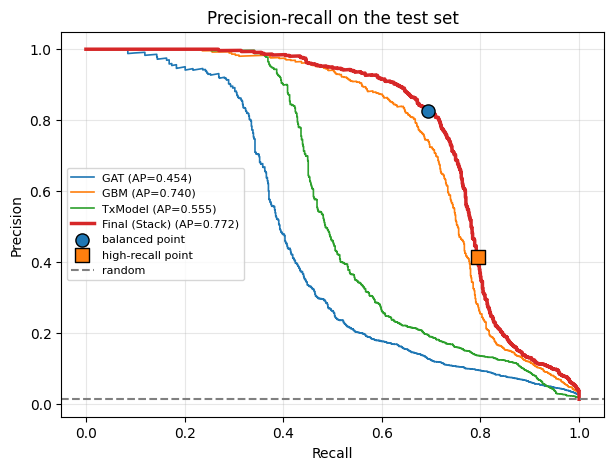

In [53]:
fig_pr = plt.figure(figsize=(7, 5))
for name, p in [("GAT", gnn_test), ("GBM", gbm_test), ("TxModel", edge_test), (f"Final ({final_name})", final_test)]:
    pr, rc, _ = precision_recall_curve(ty, p)
    plt.plot(rc, pr, lw=2.5 if name.startswith("Final") else 1.2, label=f"{name} (AP={average_precision_score(ty, p):.3f})")
for lab_, t, mk in [("balanced", t_bal, "o"), ("high-recall", t_hr, "s")]:
    r = eval_at(ty, final_test, t); plt.scatter(r["recall"], r["precision"], s=90, marker=mk, zorder=5, edgecolor="k", label=f"{lab_} point")
plt.axhline(ty.mean(), ls="--", c="gray", label="random")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-recall on the test set")
plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()

## 14. Save the GAT checkpoint only

(Only the GAT weights go in this file. Section 15 logs **all** models, parameters and metrics with MLflow.)

In [54]:
import os, json, joblib, numpy as np, pandas as pd, torch

OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
SAVE_DIR = f"{OUT}/aml_best_model"
os.makedirs(SAVE_DIR, exist_ok=True)

# 1) GAT weights + the arguments needed to rebuild the architecture
torch.save({"state_dict": best_state,
            "init_args": dict(in_ch=data.num_node_features, edge_dim=data.edge_attr.size(1),
                              hidden=CFG["hidden"], heads=CFG["heads"], dropout=CFG["dropout"])},
           f"{SAVE_DIR}/gat.pt")

# 2) every scikit-learn component of the ensemble
stack_folds = globals().get("stack_models")
if final_name == "Stack" and not stack_folds:
    print("WARNING: final scorer is the Stacker but its fold models were not kept; re-run the stacker cell, "
          "adding `stack_models.append(m_)` inside its loop, then run this cell again.")
joblib.dump({"scaler": scaler, "node_gbm": gbm, "tx_gbm": egbm, "stacker_folds": stack_folds},
            f"{SAVE_DIR}/sklearn_models.joblib")

# 3) settings needed to reproduce the predictions
meta = {
    "final_scorer": final_name,                                   # "Blend" or "Stack"
    "blend_weights": {"gat": wa, "gbm": wb, "tx": wc},
    "thresholds_on_rank": {"balanced": t_bal, "high_recall": t_hr},   # thresholds are on RANK scores (0-1 percentile)
    "test_metrics": {"balanced": eval_at(ty, final_test, t_bal), "high_recall": eval_at(ty, final_test, t_hr)},
    "test_results_by_model": results.to_dict(),
    "operating_points": ops.to_dict(),
    "feature_names": feature_names, "currencies": currencies, "formats": formats,
    "usd_per_unit": {k: float(v) for k, v in rate.items()},
    "config": CFG,
}
with open(f"{SAVE_DIR}/metadata.json", "w") as f:
    json.dump(meta, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

# 4) account IDs, the split, and the known-label vector (needed to rebuild the label-aware features)
np.savez_compressed(f"{SAVE_DIR}/graph_ids_and_split.npz", accounts=np.array(uniques.astype(str)),
                    train_nodes=train_nodes, val_nodes=val_nodes, test_nodes=test_nodes,
                    known=known if known is not None else np.zeros(0))

# 5) the final predictions: one row per test account
pd.DataFrame({"account": np.array(uniques)[test_nodes], "true_label": ty.astype(int),
              "suspicion_rank": final_test,
              "flag_balanced": (final_test >= t_bal).astype(int),
              "flag_high_recall": (final_test >= t_hr).astype(int)}
             ).sort_values("suspicion_rank", ascending=False).to_csv(f"{SAVE_DIR}/test_predictions.csv", index=False)

# 6) quick check: reload and confirm the saved models reproduce the in-memory predictions
bundle = joblib.load(f"{SAVE_DIR}/sklearn_models.joblib")
assert np.allclose(bundle["node_gbm"].predict_proba(Xg[test_nodes])[:, 1], gbm_test)
assert all(torch.equal(v.cpu(), best_state[k].cpu()) for k, v in torch.load(f"{SAVE_DIR}/gat.pt")["state_dict"].items())
print("Saved and verified ->", SAVE_DIR)
for fn in sorted(os.listdir(SAVE_DIR)):
    print(f"  {fn:28s} {os.path.getsize(os.path.join(SAVE_DIR, fn)) / 1e6:8.2f} MB")

Saved and verified -> /kaggle/working/aml_best_model
  gat.pt                           0.15 MB
  graph_ids_and_split.npz          4.99 MB
  metadata.json                    0.01 MB
  sklearn_models.joblib            4.36 MB
  test_predictions.csv             3.19 MB


## 15. MLflow tracking: models, parameters, metrics

One **parent run** (pipeline-level settings, final operating-point metrics, plots, inference config, the feature scaler) with four **child runs**, one per model: `gat`, `node_gbm`, `tx_gbm`, `stacker`. Each child logs its own hyperparameters, validation/test metrics and the fitted model, so you can compare them side by side in the MLflow UI.

Everything is stored locally in `mlflow.db` (metadata) and `mlartifacts/` (models, plots), in `/kaggle/working` on Kaggle. To use a remote server instead, set the `MLFLOW_TRACKING_URI` environment variable before running this cell.

In [55]:
import importlib.util, subprocess, sys, json, os, re
if importlib.util.find_spec("mlflow") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "mlflow"])
import mlflow, mlflow.sklearn, mlflow.pytorch

OUT = os.path.abspath("/kaggle/working" if os.path.isdir("/kaggle/working") else ".")
# SQLite is MLflow's supported local backend (the old ./mlruns folder backend is in maintenance mode)
TRACKING_URI = os.environ.get("MLFLOW_TRACKING_URI", f"sqlite:///{OUT}/mlflow.db")
mlflow.set_tracking_uri(TRACKING_URI)
EXP = "aml-gnn-account-classification"
if mlflow.get_experiment_by_name(EXP) is None:
    mlflow.create_experiment(EXP, artifact_location=f"file:{OUT}/mlartifacts") if TRACKING_URI.startswith("sqlite") \
        else mlflow.create_experiment(EXP)
mlflow.set_experiment(EXP)

def log_sk(model, name, **kw):                      # cloudpickle avoids an optional 'skops' dependency
    return mlflow.sklearn.log_model(model, name, serialization_format="cloudpickle", **kw)

_clean = lambda k: re.sub(r"[^0-9a-zA-Z_\-\. /]", "_", str(k))
def log_params_safe(d, prefix=""):
    items = {_clean(prefix + k): (json.dumps(v) if isinstance(v, (list, tuple, dict)) else str(v))[:500] for k, v in d.items()}
    keys = list(items)
    for i in range(0, len(keys), 90):                     # MLflow accepts <=100 params per call
        mlflow.log_params({k: items[k] for k in keys[i:i + 90]})
def log_metrics_safe(d, step=None):
    mlflow.log_metrics({_clean(k): float(v) for k, v in d.items() if np.isfinite(v)}, step=step)

# ---------- numbers shared by several runs ----------
test_row = {m: results.loc[m].to_dict() for m in results.index}                 # GAT, GBM, TxModel, Blend (test)
t_stack, _ = best_f1_threshold(vy, stack_val)
test_row["Stack"] = {k: v for k, v in report("Stack", ty, stack_test, t_stack).items() if k != "model"}
val_ap = {"GAT": average_precision_score(vy, gnn_val), "GBM": average_precision_score(vy, gbm_val),
          "TxModel": average_precision_score(vy, edge_val), "Blend": average_precision_score(vy, blend_val),
          "Stack": average_precision_score(vy, stack_val)}
ops_pts = {"balanced": eval_at(ty, final_test, t_bal), "high_recall": eval_at(ty, final_test, t_hr)}

def log_child(name, params, model_key, extra_metrics, log_model):
    with mlflow.start_run(run_name=name, nested=True):
        mlflow.set_tag("model_role", name)
        log_params_safe(params)
        log_metrics_safe({f"test_{k}": v for k, v in test_row[model_key].items()})
        log_metrics_safe({"val_pr_auc": val_ap[model_key], **extra_metrics})
        log_model()

with mlflow.start_run(run_name="aml-v4-pipeline") as parent:
    mlflow.set_tags({"dataset": "IBM HI-Small_Trans", "task": "account-level laundering detection",
                     "final_scorer": final_name})

    # ---------- parent: pipeline-level parameters ----------
    log_params_safe(CFG, prefix="cfg.")
    log_params_safe({"n_accounts": N, "n_transactions": E, "n_positive_accounts": int(y.sum()),
                     "n_node_features": X.shape[1], "n_label_features": 0 if XL is None else XL.shape[1],
                     "n_tx_features": T.shape[1], "n_train": len(train_nodes), "n_val": len(val_nodes),
                     "n_test": len(test_nodes), "final_scorer": final_name,
                     "blend_w_gat": round(wa, 2), "blend_w_gbm": round(wb, 2), "blend_w_tx": round(wc, 2),
                     "threshold_balanced": round(t_bal, 6), "threshold_high_recall": round(t_hr, 6)})

    # ---------- parent: final metrics (test set, thresholds chosen on validation) ----------
    for pt, r in ops_pts.items():
        log_metrics_safe({f"final_{pt}_{k}": v for k, v in r.items()})
    log_metrics_safe({"final_val_f1_blend": val_f1, "final_val_f1_stack_oof": f_stack,
                      "final_test_pr_auc": average_precision_score(ty, final_test),
                      "final_test_roc_auc": roc_auc_score(ty, final_test)})

    # ---------- parent: artifacts ----------
    mlflow.log_figure(fig_pr, "plots/pr_curve_test.png")
    mlflow.log_text(results.to_csv(), "tables/test_results_by_model.csv")
    mlflow.log_text(ops.to_csv(), "tables/operating_points.csv")
    mlflow.log_dict({"feature_names": feature_names, "currencies": currencies, "formats": formats,
                     "usd_per_unit": {k: float(v) for k, v in rate.items()},
                     "thresholds_on_rank": {"balanced": t_bal, "high_recall": t_hr},
                     "final_scorer": final_name, "blend_weights": {"gat": wa, "gbm": wb, "tx": wc},
                     "config": CFG}, "inference_config.json")
    log_sk(scaler, "feature_scaler")

    # ---------- child 1: GAT ----------
    gat_params = {"in_channels": data.num_node_features, "edge_dim": data.edge_attr.size(1),
                  "hidden": CFG["hidden"], "heads": CFG["heads"], "dropout": CFG["dropout"],
                  "lr": CFG["lr"], "weight_decay": CFG["weight_decay"], "batch_size": CFG["batch_size"],
                  "neighbors": CFG["nbrs"], "neg_per_pos": CFG["neg_per_pos"], "max_epochs": CFG["epochs"],
                  "patience": CFG["patience"], "n_parameters": sum(p.numel() for p in model.parameters()),
                  "optimizer": "AdamW", "loss": "BCEWithLogits", "sampler": "PyG" if FAST_SAMPLER else "fallback"}
    def _log_gat():
        for h in history:
            log_metrics_safe({k: v for k, v in h.items() if k != "epoch"}, step=h["epoch"])
        log_metrics_safe({"best_val_monitor_pr_auc": best_ap, "epochs_trained": len(history)})
        gat_cpu = copy.deepcopy(model).cpu().eval()
        mlflow.pytorch.log_model(gat_cpu, "gat_model", serialization_format="pickle")   # graph inputs cannot be traced (pt2)
    log_child("gat", gat_params, "GAT", {}, _log_gat)

    # ---------- child 2: node-level gradient boosting ----------
    def _log_gbm():
        log_metrics_safe({"n_trees_used": gbm.n_iter_})
        log_sk(gbm, "node_gbm", input_example=Xg[val_nodes[:5]])
    log_child("node_gbm", {**gbm.get_params(), "n_features": Xg.shape[1], "pos_weight": round(float(w_pos), 3)},
              "GBM", {}, _log_gbm)

    # ---------- child 3: transaction-level gradient boosting ----------
    def _log_tx():
        extra = {"n_trees_used": egbm.n_iter_, "n_train_pos_tx": len(e_pos), "n_train_neg_tx": len(e_neg)}
        if laund[held].any():
            extra["held_out_tx_pr_auc"] = average_precision_score(laund[held], p_e[held])
        log_metrics_safe(extra)
        log_sk(egbm, "tx_gbm", input_example=edge_matrix(needed[:5]))
    log_child("tx_gbm", {**egbm.get_params(), "n_features": edge_matrix(needed[:1]).shape[1],
                         "neg_per_pos": CFG["edge_neg_per_pos"], "account_aggregation": "max over transactions"},
              "TxModel", {}, _log_tx)

    # ---------- child 4: stacker (5 fold-models) + blend ----------
    def _log_stack():
        log_metrics_safe({"val_f1_blend": val_f1, "val_f1_stack_oof": f_stack,
                          "test_Blend_F1": test_row["Blend"]["F1"], "test_Blend_PR_AUC": test_row["Blend"]["PR_AUC"]})
        for i, m_ in enumerate(stack_models):
            log_sk(m_, f"stacker_fold_{i}", input_example=Sv[:5])
    log_child("stacker", {**stack_models[0].get_params(), "folds": len(stack_models), "n_features": Sv.shape[1],
                          "blend_w_gat": round(wa, 2), "blend_w_gbm": round(wb, 2), "blend_w_tx": round(wc, 2),
                          "final_scorer": final_name}, "Stack", {}, _log_stack)

    print("MLflow run id:", parent.info.run_id)
    print("Tracking URI :", TRACKING_URI)
print(f"\nView the results with:\n  mlflow ui --backend-store-uri {TRACKING_URI}")

2026/10/28 00:52:38 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/28 00:52:38 INFO mlflow.store.db.utils: Updating database tables
2026/10/28 00:52:42 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/28 00:52:42 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/28 00:52:42 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2026/10/28 00:52:51 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/28 00:52:51 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format require

MLflow run id: 0bf53225efcc460fa5bd32fa564e7f59
Tracking URI : sqlite:////kaggle/working/mlflow.db

View the results with:
  mlflow ui --backend-store-uri sqlite:////kaggle/working/mlflow.db


**Loading a logged model later** (replace `<RUN_ID>` with the child run's id from the UI):

```python
gbm = mlflow.sklearn.load_model("runs:/<RUN_ID>/node_gbm")        # also tx_gbm, stacker_fold_0..4
gat = mlflow.pytorch.load_model("runs:/<RUN_ID>/gat_model")       # needs torch_geometric installed
```
`inference_config.json` (parent run) holds the thresholds, blend weights, feature order, USD rates and config needed to reproduce the pipeline.